# Case Study 18 — Customer Satisfaction Survey: Who Did We Actually Hear From?

**Sampling frames and designs (simple random, stratified, cluster, convenience) · sampling error and design effects ·
coverage, selection and non-response bias · survivorship bias · representativeness checks · post-stratification, raking
and inverse-propensity weighting · effective sample size · non-response follow-up · sensitivity analysis · why a large
biased sample is worse than a small random one**

| | |
|---|---|
| **Domain** | Customer analytics: satisfaction (NPS) measurement |
| **Stakeholders** | Head of Retail Banking, Customer Experience team |
| **Difficulty** | Beginner–Intermediate |
| **Importance** | 🟠 SHOULD GO THROUGH |
| **Builds on** | Case 01 (confidence intervals), Case 17 (missing data) |
| **Data** | 40,000 active customers (the frame); 2,058 survey responses; a 246-customer phone follow-up of non-respondents |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`. A separate **answer key** (every customer's true score) exists only because
> the data are simulated; the notebook opens it **only in Section 11**. In real life nobody knows the truth, which is
> why Sections 5–10 use only information a real analyst would have.

**What you will learn**

1. How to check **who** a survey really represents, using what you know about **everyone** you invited.
2. The kinds of survey bias (coverage, selection, non-response, survivorship) and which of them weighting can fix.
3. How to compute **post-stratification, raking and inverse-propensity weights**, and what weighting costs
   (effective sample size).
4. How to use a **non-response follow-up** and a **sensitivity analysis** to bound what you cannot fix.
5. Why a **big biased sample** can be far worse than a **small random one**.

## Section 1 — Business context

The bank emailed a one-question survey, *"How likely are you to recommend us to a friend or colleague? (0–10)"*, to all
**40,000 active customers**. **2,058** answered (5.1%). The Head of Retail Banking writes:

> *"The average score is nearly 7.9 out of 10 and the share of promoters is high. With over two thousand responses
> the margin of error is tiny, so I'd like to put '7.9, a record' in the annual report. Our Net Promoter Score
> looks excellent. Any reason not to?"*

Net Promoter Score (NPS) = % **promoters** (scores 9–10) − % **detractors** (scores 0–6).

## Section 2 — Business questions

1. What does the survey say, and how precise is it **if** the respondents were a random sample?
2. Who actually answered? Do they look like our customers?
3. Can we correct for it? How well?
4. What can we **not** correct, and how wrong could the number still be?
5. What should the annual report say, and how should we run the next survey?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | What does it say? | Mean score, promoter share, NPS with CIs, **assuming** random sampling | t / Wilson / bootstrap CIs |
| 2 | Who answered? | Is the respondent profile different from the **frame** (everyone invited)? | Frame vs respondent shares, response rates by group, standardised differences |
| 3 | Correct it? | Reweight respondents to look like the frame | Post-stratification, raking, response-propensity weights |
| 4 | What is left? | Does non-response depend on the score itself (MNAR)? | Non-response follow-up; sensitivity (tipping-point) analysis |
| 5 | Next survey | How do designs differ in precision and bias? | Simulation: simple random, stratified, cluster, convenience |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_p, rng_for_case
from statistical_tests import proportion_ci
from plotting import set_style, save_fig, add_note, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "18_survey_sampling_bias"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
rng = rng_for_case(1818)
pctfmt = plt.FuncFormatter(lambda v, _: f"{v:.0%}")

def wilson(k, n):
    ci = proportion_ci(int(k), int(n))
    return ci["lower"], ci["upper"]

## Section 4 — Load the data

In [2]:
frame = pd.read_csv(PATHS["data"] / "customer_frame.csv", dtype={"complaints_12m": str})
resp = pd.read_csv(PATHS["data"] / "survey_responses.csv")
follow = pd.read_csv(PATHS["data"] / "followup_sample.csv")
print(f"Frame: {len(frame):,} active customers;  respondents: {len(resp):,} ({len(resp) / len(frame):.1%});  follow-up reached: {len(follow)}")
print(f"Duplicate ids in frame: {frame['customer_id'].duplicated().sum()};  respondents not in frame: {(~resp['customer_id'].isin(frame['customer_id'])).sum()};  "
      f"missing scores: {resp['score'].isna().sum()}")
display(frame.head())
frame["any_complaint"] = (frame["complaints_12m"] != "0").astype(int)
frame["responded"] = frame["customer_id"].isin(resp["customer_id"]).astype(int)
age_order = ["21–29", "30–39", "40–49", "50–59", "60+"]
frame["age_band"] = pd.Categorical(frame["age_band"], categories=age_order)
frame["complaints_12m"] = pd.Categorical(frame["complaints_12m"], categories=["0", "1", "2+"])
frame["segment"] = pd.Categorical(frame["segment"], categories=["Mass", "Affluent", "Privileged"])
r = resp.merge(frame, on="customer_id")

Frame: 40,000 active customers;  respondents: 2,058 (5.1%);  follow-up reached: 246
Duplicate ids in frame: 0;  respondents not in frame: 0;  missing scores: 0


,customer_id,branch,age_band,segment,tenure_years,digital_user,products,complaints_12m,city_tier
0,CU18100000,B35,40–49,Affluent,6.9000,1,3,0,1
1,CU18100001,B36,60+,Affluent,7.3000,0,2,0,3
2,CU18100002,B15,40–49,Mass,4.3000,0,1,0,1
3,CU18100003,B03,21–29,Mass,1.0000,1,2,0,3
4,CU18100004,B19,40–49,Mass,10.7000,1,2,1,1


The frame has **everything we know about each invited customer**: age band, segment, tenure, digital usage, number of
products, complaints, city tier and branch. This is the key asset: we know what **all** customers look like, not just
the ones who answered.

## Section 5 — The headline number, taken at face value

In [3]:
def nps_parts(s, w=None):
    s = np.asarray(s); w = np.ones(len(s)) if w is None else np.asarray(w)
    w = w / w.sum()
    return (w * (s >= 9)).sum(), (w * (s <= 6)).sum()

s = r["score"].to_numpy()
n = len(s)
mean_ci = stats.t.interval(0.95, n - 1, loc=s.mean(), scale=stats.sem(s))
prom, det = nps_parts(s)
boot_nps = [(lambda b: 100 * (nps_parts(b)[0] - nps_parts(b)[1]))(rng.choice(s, n)) for _ in range(2000)]
naive = pd.DataFrame({"estimate": [s.mean(), prom, det, 100 * (prom - det)],
                      "ci_low": [mean_ci[0], wilson(prom * n, n)[0], wilson(det * n, n)[0], np.percentile(boot_nps, 2.5)],
                      "ci_high": [mean_ci[1], wilson(prom * n, n)[1], wilson(det * n, n)[1], np.percentile(boot_nps, 97.5)]},
                     index=["mean score (0–10)", "share of promoters (9–10)", "share of detractors (0–6)", "NPS (points)"])
save_table(naive, "naive_estimates", PATHS["tables"])
display(naive)
print(f"The margin of error on the mean is ±{(mean_ci[1] - mean_ci[0]) / 2:.2f} points.")

,estimate,ci_low,ci_high
mean score (0–10),7.8707,7.7989,7.9426
share of promoters (9–10),0.4004,0.3789,0.4212
share of detractors (0–6),0.2099,0.1924,0.2275
NPS (points),19.0476,15.7908,22.2060


The margin of error on the mean is ±0.07 points.


**Observation.** Taken at face value, the survey says: mean **7.87**, **40% promoters**, **21%
detractors**, NPS **+19**, with a tiny margin of error (±0.07 points on the mean).

**What this margin of error means, and what it does not.** The confidence interval measures **sampling error**:
the randomness from observing 2,058 people instead of everybody, **if they were a random sample**. It says nothing
about **bias**: respondents who differ systematically from non-respondents. More responses make the interval narrower,
but they do **not** make the estimate less biased.

## Section 6 — Who actually answered?

In [4]:
rows = []
for col in ["age_band", "digital_user", "complaints_12m", "segment", "city_tier", "products"]:
    pop = frame[col].value_counts(normalize=True)
    res = r[col].value_counts(normalize=True)
    for lvl in sorted(pop.index, key=lambda x: str(x)):
        k = (r[col] == lvl).sum(); nn = (frame[col] == lvl).sum(); kk = ((frame[col] == lvl) & (frame["responded"] == 1)).sum()
        rows.append({"variable": col, "level": str(lvl), "share of all customers": pop[lvl], "share of respondents": res.get(lvl, 0.0),
                     "ratio": res.get(lvl, 0.0) / pop[lvl], "response rate": kk / nn})
rep = pd.DataFrame(rows).set_index(["variable", "level"])
save_table(rep, "representativeness", PATHS["tables"])
display(rep)
num_rows = []
for col in ["tenure_years"]:
    a, b = r[col], frame.loc[frame["responded"] == 0, col]
    num_rows.append({"variable": col, "respondents (mean)": a.mean(), "non-respondents (mean)": b.mean(),
                     "standardised difference": (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)})
display(pd.DataFrame(num_rows).set_index("variable"))

share of all customers  share of respondents  \
variable       level                                                      
age_band       21–29                       0.1348                0.0476   
               30–39                       0.2339                0.1433   
               40–49                       0.2976                0.2502   
               50–59                       0.2153                0.2901   
               60+                         0.1184                0.2687   
digital_user   0                           0.2099                0.1764   
               1                           0.7902                0.8236   
complaints_12m 0                           0.8004                0.8941   
               1                           0.1405                0.0787   
               2+                          0.0591                0.0272   
segment        Affluent                    0.2341                0.2362   
               Mass                        0.7153                0.7245   
               Privileged                  0.0505                0.0394   
city_tier      1                           0.3993                0.3916   
               2                           0.3814                0.3698   
               3                           0.2193                0.2386   
products       1                           0.4723                0.4422   
               2                           0.3368                0.3392   
               3                           0.1377                0.1560   
               4                           0.0532                0.0627   

                           ratio  response rate  
variable       level                             
age_band       21–29      0.3533         0.0182  
               30–39      0.6127         0.0315  
               40–49      0.8409         0.0433  
               50–59      1.3475         0.0693  
               60+        2.2695         0.1168  
digital_user   0          0.8405         0.0432  
               1          1.0424         0.0536  
complaints_12m 0          1.1170         0.0575  
               1          0.5602         0.0288  
               2+         0.4606         0.0237  
segment        Affluent   1.0085         0.0519  
               Mass       1.0128         0.0521  
               Privileged 0.7790         0.0401  
city_tier      1          0.9808         0.0505  
               2          0.9696         0.0499  
               3          1.0879         0.0560  
products       1          0.9361         0.0482  
               2          1.0070         0.0518  
               3          1.1327         0.0583  
               4          1.1793         0.0607

,respondents (mean),non-respondents (mean),standardised difference
variable,,,
tenure_years,6.0860,5.5456,0.0979


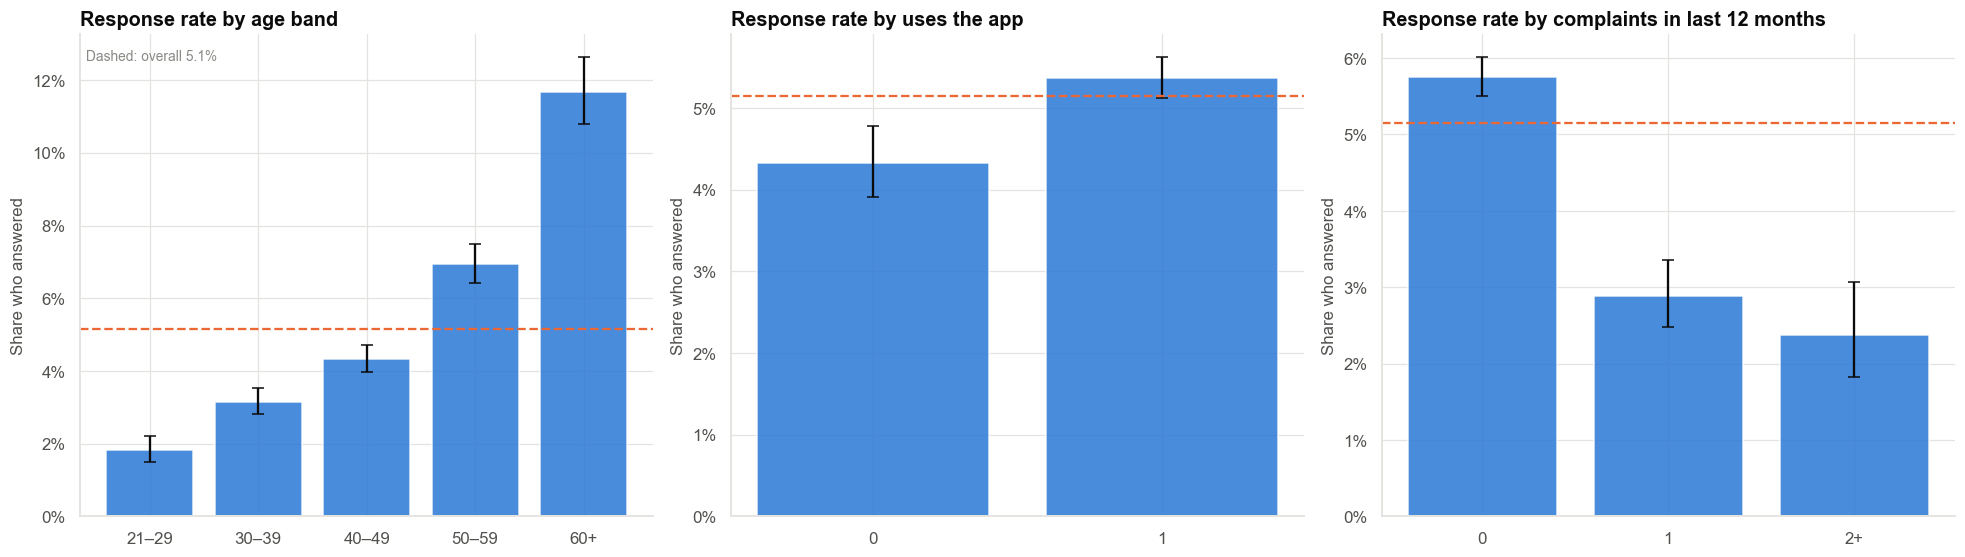

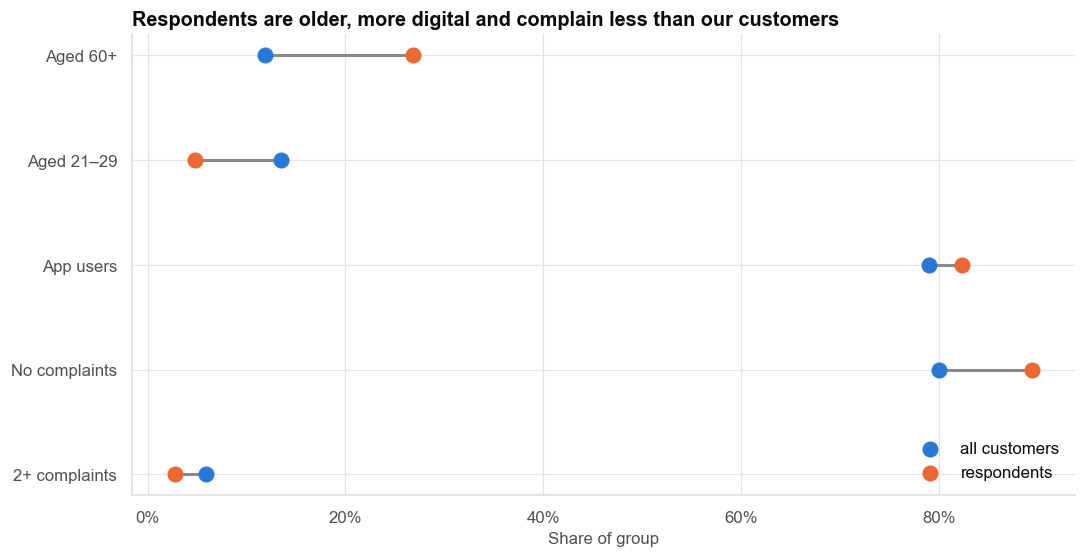

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for ax, col, lab in [(axes[0], "age_band", "Age band"), (axes[1], "digital_user", "Uses the app"), (axes[2], "complaints_12m", "Complaints in last 12 months")]:
    g = frame.groupby(col, observed=True)["responded"].agg(["sum", "size"])
    rate = g["sum"] / g["size"]
    ci = np.array([wilson(k, n_) for k, n_ in zip(g["sum"], g["size"])])
    ax.bar([str(i) for i in g.index], rate, color=PRIMARY, alpha=0.85)
    ax.errorbar(range(len(g)), rate, yerr=[rate - ci[:, 0], ci[:, 1] - rate], fmt="none", color=INK, capsize=4)
    ax.axhline(frame["responded"].mean(), color=HIGHLIGHT, ls="--", lw=1.5)
    ax.yaxis.set_major_formatter(pctfmt)
    ax.set(title=f"Response rate by {lab.lower()}", ylabel="Share who answered")
add_note(axes[0], "Dashed: overall 5.1%", "upper left")
fig.tight_layout()
save_fig(fig, "fig01_response_rates", PATHS["figures"])
plt.show()

fig, ax = plt.subplots(figsize=(10, 5.2))
pairs = [("age_band", "60+"), ("age_band", "21–29"), ("digital_user", 1), ("complaints_12m", "0"), ("complaints_12m", "2+")]
labs = ["Aged 60+", "Aged 21–29", "App users", "No complaints", "2+ complaints"]
y_ = np.arange(len(pairs))[::-1]
for yi, (col, lvl), lab in zip(y_, pairs, labs):
    pop = (frame[col] == lvl).mean(); res = (r[col] == lvl).mean()
    ax.plot([pop, res], [yi, yi], color=INK_MUTED, lw=2)
    ax.scatter(pop, yi, color=PRIMARY, s=90, zorder=3, label="all customers" if yi == y_[0] else None)
    ax.scatter(res, yi, color=HIGHLIGHT, s=90, zorder=3, label="respondents" if yi == y_[0] else None)
ax.set_yticks(y_, labs); ax.xaxis.set_major_formatter(pctfmt)
ax.set(xlabel="Share of group", title="Respondents are older, more digital and complain less than our customers")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
save_fig(fig, "fig02_respondent_profile", PATHS["figures"])
plt.show()

**Observation.**
- **Older** customers answer far more often than younger ones; **app users** answer more than non-users; customers
  **with complaints** answer **less** than average.
- Compared with all customers, respondents are older, more digital, and contain too few customers with complaints.
- Response rates range from under 2% to about 12% across groups, a six-fold range. A survey is representative only if
  every group has a similar response rate (or if we correct for the differences).

**Interpretation.** Because we know the frame, we can see exactly **how** the respondents differ on the variables we
have. What we cannot see in this table is whether, **within** a group (say, app users aged 40–49 with no complaints),
the happy ones answer more than the unhappy ones. That would be non-response related to the score itself.

> **Bias is about the answer, not the sample size.** 2,058 respondents who are not like our customers can be less
> informative than 400 who are.

## Section 7 — Method selection: sampling designs, biases and weighting

**Sampling designs**

| Design | How the sample is drawn | Strength | Weakness |
|---|---|---|---|
| **Simple random** | Every customer has the same chance | Simple; textbook formulas | Needs a complete list |
| **Stratified** | Random sample within groups (strata) | Lower variance if strata differ; guarantees small groups | Needs the stratum for everyone |
| **Cluster** | Random branches, then customers within them | Cheap and practical | **Higher variance** (design effect): customers in a branch resemble each other |
| **Systematic** | Every k-th customer | Easy | Danger if the list has a pattern |
| **Convenience / voluntary** | Whoever is available or chooses to respond | Cheap | **Selection bias**, no valid error bounds |
| **Quota** | Fill demographic quotas non-randomly | Looks balanced | Within-quota selection is still biased |

Our email survey is a **voluntary-response** survey: a census invitation followed by self-selection.

**Kinds of survey bias**

| Bias | What happens | Here |
|---|---|---|
| **Coverage** | The frame misses part of the population | Customers who **left** during the year are not on the list |
| **Selection / self-selection** | People choose whether to take part | Voluntary email response |
| **Non-response** | Respondents differ from non-respondents | Older, digital and happier customers answer more |
| **Survivorship** | Only the "survivors" are observed | Dissatisfied leavers are invisible |
| **Measurement** | The question or mode changes the answer | Not studied here |

**Weighting methods** (give each respondent a weight so respondents look like the frame):

| Method | Idea | Needs | Limitation |
|---|---|---|---|
| **Post-stratification** | Weight = (population cell size) / (respondent cell size) | Population counts for the **joint** cells | Sparse cells; few variables |
| **Raking** (iterative proportional fitting) | Adjust weights until **margins** of several variables match | Population counts for each margin | Corrects only what is in the margins |
| **Inverse-propensity (response) weighting** | Weight = 1 / P(respond), from a model fitted on the frame | Covariates for **everyone** | Extreme weights; model must be right |

**All three assume the data are Missing At Random given the weighting variables** (Case 17): within each weighting
cell, respondents resemble non-respondents. They cannot correct for non-response that depends on the score itself.

## Section 8 — Weighting

In [6]:
N_pop = len(frame)
cells = ["age_band", "digital_user", "any_complaint"]
pop_cell = frame.groupby(cells, observed=True).size()
resp_cell = r.groupby(cells, observed=True).size()
print(f"Post-stratification cells: {len(pop_cell)} (age band × app user × any complaint); empty among respondents: {len(set(pop_cell.index) - set(resp_cell.index))}")
w_cell = (pop_cell / resp_cell)
r["w_ps"] = [w_cell[tuple(x)] for x in r[cells].to_numpy()]

def rake(df, margins, max_iter=200, tol=1e-8):
    w = np.ones(len(df))
    for it in range(max_iter):
        w_old = w.copy()
        for col, target in margins.items():
            cur = pd.Series(w).groupby(df[col].to_numpy()).sum()
            factor = (target / cur)
            w = w * df[col].map(factor).to_numpy(dtype=float)
        if np.abs(w - w_old).max() < tol:
            break
    return w * (N_pop / w.sum()), it + 1

rake_cols = ["age_band", "digital_user", "complaints_12m", "segment", "city_tier"]
margins = {c: frame[c].value_counts() for c in rake_cols}
r["w_rake"], iters = rake(r, margins)
print(f"Raking converged in {iters} iterations; weighted margins now match the population margins on {', '.join(rake_cols)}")

prop_model = smf.logit("responded ~ C(age_band) + digital_user + C(complaints_12m) + C(segment) + C(city_tier) + tenure_years + products", frame).fit(disp=0)
frame["p_resp"] = prop_model.predict(frame)
r["p_resp"] = frame.set_index("customer_id").loc[r["customer_id"], "p_resp"].to_numpy()
r["w_ipw"] = (1 / r["p_resp"]) * (N_pop / (1 / r["p_resp"]).sum())
cap = np.quantile(r["w_ipw"], 0.99)
r["w_ipw_trim"] = np.minimum(r["w_ipw"], cap)
r["w_ipw_trim"] = r["w_ipw_trim"] * (N_pop / r["w_ipw_trim"].sum())
print(f"Response-propensity model: AUC {__import__('sklearn.metrics', fromlist=['roc_auc_score']).roc_auc_score(frame['responded'], frame['p_resp']):.3f}; "
      f"propensities range {frame['p_resp'].min():.3f}–{frame['p_resp'].max():.3f}")

wd = []
for name, col in [("Post-stratification", "w_ps"), ("Raking", "w_rake"), ("Inverse propensity", "w_ipw"), ("Inverse propensity, trimmed at 99th pct", "w_ipw_trim")]:
    w = r[col].to_numpy(); deff = 1 + (w.std() / w.mean()) ** 2
    wd.append({"weights": name, "min": w.min(), "median": np.median(w), "max": w.max(), "max ÷ median": w.max() / np.median(w),
               "design effect (Kish)": deff, "effective sample size": len(w) / deff})
wd = pd.DataFrame(wd).set_index("weights")
save_table(wd, "weight_diagnostics", PATHS["tables"])
wd

Post-stratification cells: 20 (age band × app user × any complaint); empty among respondents: 0
Raking converged in 9 iterations; weighted margins now match the population margins on age_band, digital_user, complaints_12m, segment, city_tier


Response-propensity model: AUC 0.688; propensities range 0.003–0.223


,min,median,max,max ÷ median,design effect (Kish),effective sample size
weights,,,,,,
Post-stratification,6.8149,18.7550,245.0000,13.0632,1.6251,"1,266.3769"
Raking,5.2771,16.9052,190.3735,11.2612,1.5556,"1,323.0034"
Inverse propensity,4.8056,16.4070,213.1504,12.9915,1.5682,"1,312.3714"
"Inverse propensity, trimmed at 99th pct",4.8774,16.6522,72.7613,4.3695,1.4459,"1,423.3065"


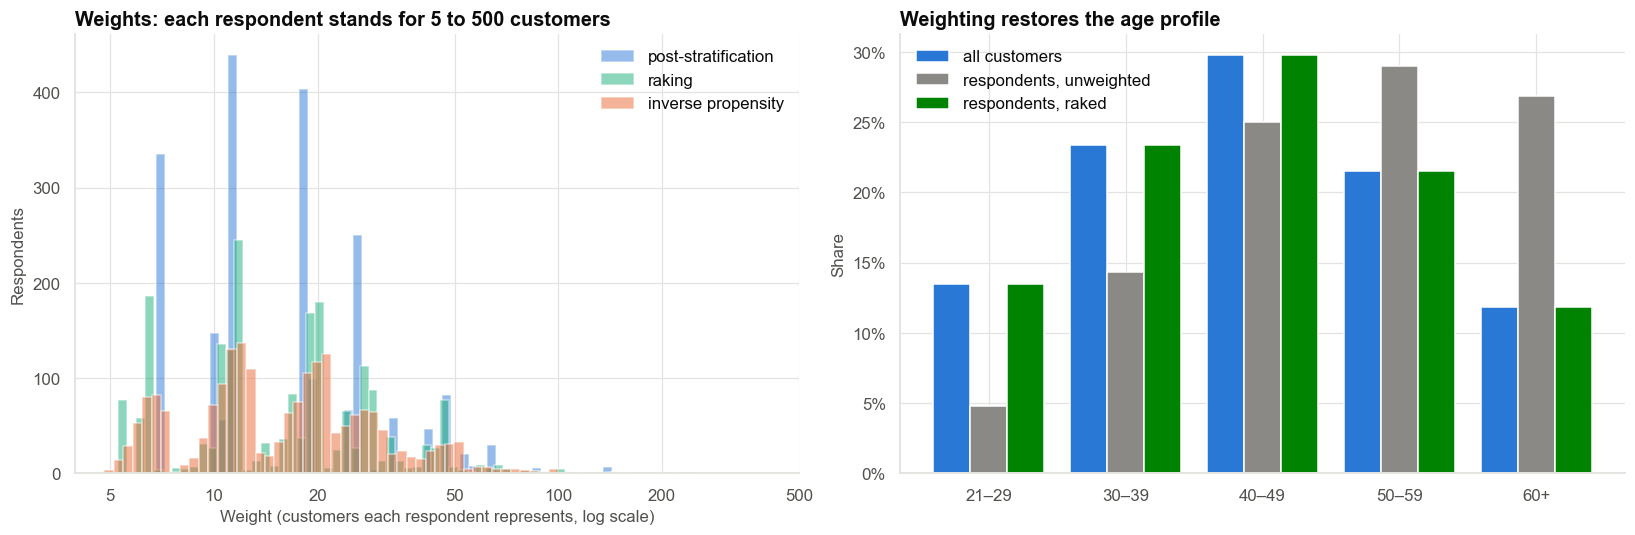

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
for col, c, lab in [("w_ps", PRIMARY, "post-stratification"), ("w_rake", COLORS["aqua"], "raking"), ("w_ipw", HIGHLIGHT, "inverse propensity")]:
    ax.hist(np.log10(r[col]), bins=60, alpha=0.5, color=c, label=lab)
ax.set_xticks(np.log10([5, 10, 20, 50, 100, 200, 500]), ["5", "10", "20", "50", "100", "200", "500"])
ax.set(xlabel="Weight (customers each respondent represents, log scale)", ylabel="Respondents", title="Weights: each respondent stands for 5 to 500 customers")
ax.legend(frameon=False)
ax = axes[1]
bands = r.groupby("age_band", observed=True)["w_rake"].agg(["sum"]).rename(columns={"sum": "weighted respondents"})
bands["customers"] = frame["age_band"].value_counts()
bands["unweighted respondents"] = r["age_band"].value_counts()
x = np.arange(len(bands))
ax.bar(x - 0.27, bands["customers"] / bands["customers"].sum(), width=0.27, color=PRIMARY, label="all customers")
ax.bar(x, bands["unweighted respondents"] / bands["unweighted respondents"].sum(), width=0.27, color=INK_MUTED, label="respondents, unweighted")
ax.bar(x + 0.27, bands["weighted respondents"] / bands["weighted respondents"].sum(), width=0.27, color=COLORS["green"], label="respondents, raked")
ax.set_xticks(x, bands.index); ax.yaxis.set_major_formatter(pctfmt)
ax.set(title="Weighting restores the age profile", ylabel="Share")
ax.legend(frameon=False)
fig.tight_layout()
save_fig(fig, "fig03_weights", PATHS["figures"])
plt.show()

**Observation.**
- Weights range from about 5 to 245 (max ÷ median about 11–13): a respondent from a low-response group (a young non-app user with
  complaints) counts for far more than a typical one.
- The **design effect** (Kish: 1 + CV² of the weights) is about 1.5–1.6, so the **effective sample size** falls from
  2,058 to roughly 1,270–1,420 (raking: 1,323): weighting costs precision.
- Raking makes the weighted age profile (and the other margins) match the customer base.

**Interpretation.** Weighting buys **less bias** at the price of **more variance**. Extreme weights, from groups with
very few respondents, make estimates unstable: trimming the propensity weights at the 99th percentile cuts the largest from 213 to 73 and
raises the effective sample size from 1,312 to 1,423 (a small bias-variance trade-off).

### 8.1 Weighted estimates

In [8]:
def estimates(df, wcol):
    w = df[wcol].to_numpy() if wcol else np.ones(len(df)); sc = df["score"].to_numpy()
    p_, d_ = nps_parts(sc, w)
    return np.array([np.average(sc, weights=w), p_, d_, 100 * (p_ - d_)])

names = ["mean score", "promoters", "detractors", "NPS"]
est = {"Unweighted (naive)": estimates(r, None), "Post-stratified": estimates(r, "w_ps"), "Raked": estimates(r, "w_rake"),
       "Inverse propensity": estimates(r, "w_ipw"), "Inverse propensity, trimmed": estimates(r, "w_ipw_trim")}
# Bootstrap: resample respondents and recompute the weights (post-stratification and raking use the fixed population margins).
B = 300
boots = {k: [] for k in est}
for _ in range(B):
    b = r.iloc[rng.integers(0, len(r), len(r))].copy()
    boots["Unweighted (naive)"].append(estimates(b, None))
    rc = b.groupby(cells, observed=True).size()
    wc_ = (pop_cell / rc).to_dict()
    b["w_ps"] = [wc_.get(tuple(x), np.nan) for x in b[cells].to_numpy()]
    boots["Post-stratified"].append(estimates(b.dropna(subset=["w_ps"]), "w_ps"))
    b["w_rake"], _ = rake(b, margins, max_iter=50, tol=1e-6)
    boots["Raked"].append(estimates(b, "w_rake"))
    b["w_ipw"] = 1 / b["p_resp"]
    boots["Inverse propensity"].append(estimates(b, "w_ipw"))
    b["w_ipw_trim"] = np.minimum(b["w_ipw"], np.quantile(b["w_ipw"], 0.99))
    boots["Inverse propensity, trimmed"].append(estimates(b, "w_ipw_trim"))
rows = []
for k, v in est.items():
    bb = np.array(boots[k])
    for i, nm in enumerate(names):
        sc_ = 100 if nm in ("promoters", "detractors") else 1
        rows.append({"estimator": k, "measure": nm, "estimate": v[i] * (100 if nm in ("promoters", "detractors") else 1),
                     "ci_low": np.percentile(bb[:, i], 2.5) * (100 if nm in ("promoters", "detractors") else 1),
                     "ci_high": np.percentile(bb[:, i], 97.5) * (100 if nm in ("promoters", "detractors") else 1)})
wt = pd.DataFrame(rows)
wt_piv = wt.pivot(index="estimator", columns="measure", values="estimate").loc[list(est)][names]
wt_ci = wt[wt["measure"] == "mean score"].set_index("estimator").loc[list(est)][["estimate", "ci_low", "ci_high"]]
save_table(wt, "weighted_estimates_long", PATHS["tables"])
save_table(wt_ci, "weighted_mean_score_ci", PATHS["tables"])
display(wt_piv.rename(columns={"promoters": "promoters (%)", "detractors": "detractors (%)", "NPS": "NPS (points)"}))
wt_ci

measure,mean score,promoters (%),detractors (%),NPS (points)
estimator,,,,
Unweighted (naive),7.8707,40.0389,20.9913,19.0476
Post-stratified,7.6616,35.8481,25.1897,10.6584
Raked,7.6343,35.3796,25.8930,9.4866
Inverse propensity,7.6245,35.0392,26.0133,9.0259
"Inverse propensity, trimmed",7.6519,35.4674,25.3164,10.1511


,estimate,ci_low,ci_high
estimator,,,
Unweighted (naive),7.8707,7.8020,7.9441
Post-stratified,7.6616,7.5771,7.7456
Raked,7.6343,7.5535,7.7203
Inverse propensity,7.6245,7.5121,7.7180
"Inverse propensity, trimmed",7.6519,7.5522,7.7470


**Observation.** Weighting lowers the estimated mean score from 7.87 to **7.62–7.66**, and the NPS from +19 to
**+9 to +11**. The four weighting methods agree within 0.04 points. The bootstrap intervals (about ±0.08–0.10) are
wider than the naive ±0.07, reflecting the lower effective sample size.

**Interpretation.** About **0.24 points (30%)** of the naive overstatement is explained by *who* answered (older, digital,
non-complaining customers). That part we can fix, because we know those characteristics for everyone. Whether that is
all the bias is another matter: weighting cannot fix the part related to the score itself.

In [9]:
f_s = follow["score"].to_numpy()
nf = len(f_s)
f_ci = stats.t.interval(0.95, nf - 1, loc=f_s.mean(), scale=stats.sem(f_s))
rr = len(r) / N_pop
comb = rr * r["score"].mean() + (1 - rr) * f_s.mean()
se_comb = (1 - rr) * f_s.std(ddof=1) / np.sqrt(nf)
fu = pd.DataFrame({"mean score": [r["score"].mean(), f_s.mean(), comb],
                   "ci_low": [mean_ci[0], f_ci[0], comb - 1.96 * se_comb], "ci_high": [mean_ci[1], f_ci[1], comb + 1.96 * se_comb],
                   "n": [len(r), nf, N_pop]},
                  index=["email respondents (5.1% of customers)", "phone follow-up of non-respondents (random sample)", "combined estimate for ALL active customers"])
save_table(fu, "followup_estimate", PATHS["tables"])
display(fu)
print(f"Difference between respondents and non-respondents: {r['score'].mean() - f_s.mean():+.2f} points "
      f"(Welch t-test p = {fmt_p(stats.ttest_ind(r['score'], f_s, equal_var=False).pvalue)})")

,mean score,ci_low,ci_high,n
email respondents (5.1% of customers),7.8707,7.7989,7.9426,2058
phone follow-up of non-respondents (random sample),7.2764,7.0568,7.4960,246
combined estimate for ALL active customers,7.3070,7.0997,7.5143,40000


Difference between respondents and non-respondents: +0.59 points (Welch t-test p = < 0.001)


**Observation.** Randomly sampled non-respondents who were reached score **0.59 points lower** than the email
respondents (7.28 vs 7.87, Welch p < 0.001). The combined estimate for all active customers is **7.31**
(95% CI 7.10–7.51), well below the naive 7.87 and below the weighted 7.63.

**Interpretation.** A **non-response follow-up** is the most direct way to measure non-response bias: a small
**random** sample of non-respondents, contacted by a stronger method. 246 well-chosen people tell us more about the
other 38,000 than 2,058 volunteers do. The raw respondent-versus-follow-up gap (0.59) is larger than the gap between the
*weighted* respondents and the follow-up (0.36): weighting has already removed part of it.

**Caveats.** Only 246 of the 400 sampled non-respondents (60%) were reached, and the people who pick up the phone may be
happier than those who do not (Section 11 checks this against the answer key). Phone mode may also change answers.

In [10]:
w_rake_mean = est["Raked"][0]
resp_share = rr
rows = []
for gap in [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]:
    # Population mean if non-respondents score `gap` lower than the weighted respondents (who stand in for the cell average).
    mean_all = w_rake_mean - (1 - resp_share) * gap
    rows.append({"non-respondents lower by (points)": gap, "implied mean score, all customers": mean_all})
tip = pd.DataFrame(rows).set_index("non-respondents lower by (points)")
tip["conclusion 'score ≥ 7.5'"] = np.where(tip["implied mean score, all customers"] >= 7.5, "holds", "fails")
tip["conclusion 'score ≥ 7.0'"] = np.where(tip["implied mean score, all customers"] >= 7.0, "holds", "fails")
save_table(tip, "tipping_point", PATHS["tables"])
print(f"Weighted (raked) respondents' mean: {w_rake_mean:.2f}.  Gap needed to fall below 7.5: {(w_rake_mean - 7.5) / (1 - resp_share):.2f} points;  below 7.0: {(w_rake_mean - 7.0) / (1 - resp_share):.2f} points")
print(f"Gap observed in the follow-up (weighted-respondent mean − follow-up mean): {w_rake_mean - f_s.mean():.2f} points")
tip

Weighted (raked) respondents' mean: 7.63.  Gap needed to fall below 7.5: 0.14 points;  below 7.0: 0.67 points
Gap observed in the follow-up (weighted-respondent mean − follow-up mean): 0.36 points


,"implied mean score, all customers",conclusion 'score ≥ 7.5',conclusion 'score ≥ 7.0'
non-respondents lower by (points),,,
0.0000,7.6343,holds,holds
0.2000,7.4446,fails,holds
0.4000,7.2549,fails,holds
0.6000,7.0652,fails,holds
0.8000,6.8755,fails,fails
1.0000,6.6858,fails,fails


**Observation.** If non-respondents score only **0.14 points** lower than the weighted respondents, the average falls
below 7.5; at 0.67 points lower it falls below 7.0. The follow-up shows a gap of **0.36 points**, which is inside that
range: with a gap of 0.36 the implied all-customer mean is about 7.3, and the claim "7.5 or better" fails.

**Interpretation.** A **tipping-point analysis** does not claim to know the truth; it shows how much hidden bias the
conclusion can survive. With a 95% non-response rate, **even small differences matter**, because the non-respondents are
almost the entire population. This is why very low response rates (below 10%) call for a follow-up study before any
number goes into a report.

In [11]:
key = pd.read_csv(PATHS["data"] / "answer_key_teaching_only.csv")
act = key[key["status"] == "active"]
left = key[key["status"] == "left"]
true_mean, true_all = act["true_score"].mean(), key["true_score"].mean()
tp, td = nps_parts(act["true_score"])
print(f"TRUTH for the 40,000 active customers: mean {true_mean:.3f}, promoters {100 * tp:.1f}%, detractors {100 * td:.1f}%, NPS {100 * (tp - td):+.1f}")
print(f"Customers who left during the year (6,000): mean {left['true_score'].mean():.2f};  everyone who was a customer this year: mean {true_all:.3f}")

g = []
for k in est:
    sub = wt[wt["estimator"] == k].set_index("measure")
    g.append({"estimator": k, "mean score": sub.loc["mean score", "estimate"], "bias": sub.loc["mean score", "estimate"] - true_mean,
              "ci_low": sub.loc["mean score", "ci_low"], "ci_high": sub.loc["mean score", "ci_high"],
              "CI covers the truth?": bool(sub.loc["mean score", "ci_low"] <= true_mean <= sub.loc["mean score", "ci_high"]),
              "NPS": sub.loc["NPS", "estimate"], "NPS bias": sub.loc["NPS", "estimate"] - 100 * (tp - td)})
g.append({"estimator": "Phone follow-up combined", "mean score": comb, "bias": comb - true_mean, "ci_low": comb - 1.96 * se_comb, "ci_high": comb + 1.96 * se_comb,
          "CI covers the truth?": bool(comb - 1.96 * se_comb <= true_mean <= comb + 1.96 * se_comb), "NPS": np.nan, "NPS bias": np.nan})
grade = pd.DataFrame(g).set_index("estimator")
save_table(grade, "estimator_grading", PATHS["tables"])
grade

# How happy are the non-respondents really, and how well does the reachable 60% represent them?
non_truth = act[~act["customer_id"].isin(r["customer_id"])]["true_score"].mean()
print(f"Truth for ALL non-respondents: {non_truth:.2f}; phone follow-up (reached 60%): {f_s.mean():.2f}; email respondents: {r['score'].mean():.2f}")


TRUTH for the 40,000 active customers: mean 7.071, promoters 23.6%, detractors 36.9%, NPS -13.2
Customers who left during the year (6,000): mean 5.23;  everyone who was a customer this year: mean 6.831
Truth for ALL non-respondents: 7.03; phone follow-up (reached 60%): 7.28; email respondents: 7.87


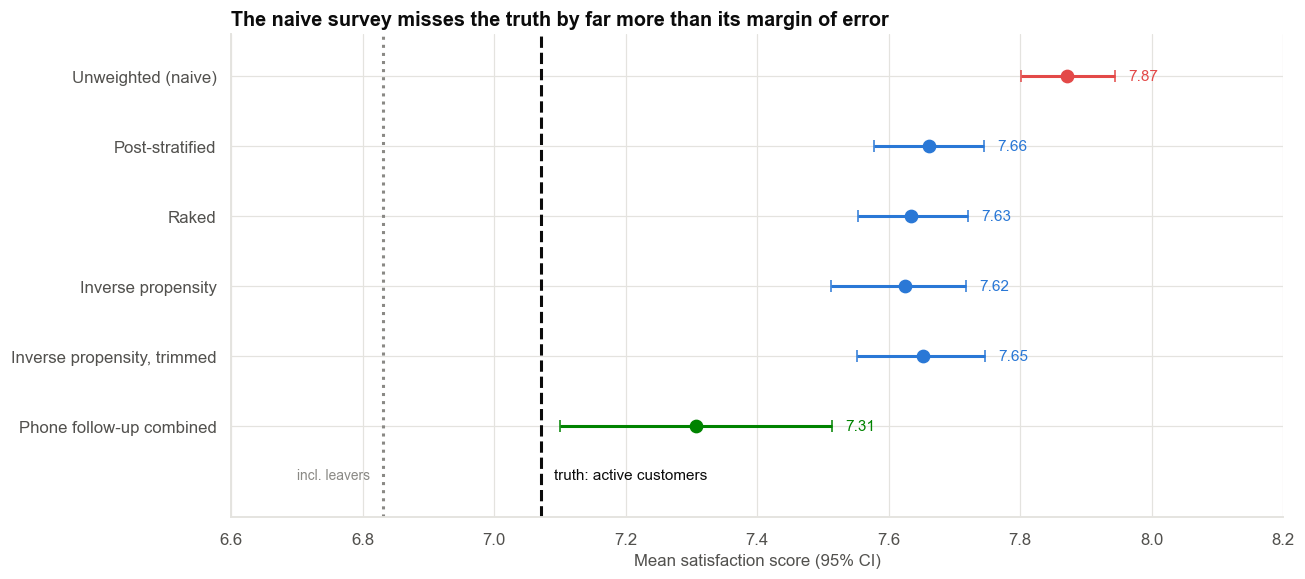

In [12]:
fig, ax = plt.subplots(figsize=(12, 5.4))
order_ = list(grade.index)[::-1]
cols = {"Unweighted (naive)": COLORS["red"], "Phone follow-up combined": COLORS["green"]}
for i, k in enumerate(order_):
    rr_ = grade.loc[k]
    c = cols.get(k, PRIMARY)
    ax.errorbar(rr_["mean score"], i, xerr=[[rr_["mean score"] - rr_["ci_low"]], [rr_["ci_high"] - rr_["mean score"]]], fmt="o", color=c, capsize=4, ms=8, lw=2)
    ax.text(rr_["ci_high"] + 0.02, i, f"{rr_['mean score']:.2f}", va="center", fontsize=10, color=c)
ax.axvline(true_mean, color=INK, ls="--", lw=2); ax.text(true_mean + 0.02, -0.75, "truth: active customers", ha="left", fontsize=10)
ax.axvline(true_all, color=INK_MUTED, ls=":", lw=2); ax.text(true_all - 0.02, -0.75, "incl. leavers", ha="right", fontsize=9, color=INK_MUTED)
ax.set_yticks(range(len(order_)), order_)
ax.set(xlabel="Mean satisfaction score (95% CI)", title="The naive survey misses the truth by far more than its margin of error", xlim=(6.6, 8.2), ylim=(-1.3, len(order_) - 0.4))
fig.tight_layout()
save_fig(fig, "fig04_estimator_grading", PATHS["figures"])
plt.show()

**Observation.** The truth for the 40,000 active customers is a mean of **7.07** and an NPS of **−13**. The naive survey
reports 7.87 and +19, so it is wrong by **+0.80 points** and **32 NPS points**, and its tight interval (7.80–7.94) is nowhere
near the truth. The real NPS is *negative*.

- **Weighting helps but does not rescue it.** Post-stratification, raking and inverse-propensity weights cut the bias to
  **+0.55 to +0.59** (about 30% of it removed). None of their 95% intervals contains the truth.
- **Why:** in this simulation happier customers respond more *even within a weighting cell* (non-response depends on the
  score itself: MNAR). Weighting can only fix response differences that are explained by variables on the frame.
- **The phone follow-up is the best estimate** (7.31, bias +0.24) but its interval (7.10–7.51) also just misses 7.07,
  because the reachable 60% of non-respondents are still happier than the unreachable 40% (see the line printed below the table).
- **Survivorship.** The 6,000 customers who **left** scored 5.23. Including them, the experience of everyone the bank
  served this year averaged **6.83**. No survey of current customers can show that.

**Interpretation.** Every interval we computed was a statement about *sampling error* only. The biggest error in this
problem was *bias*, and no confidence interval measured it.

In [13]:
pop = frame.merge(act[["customer_id", "true_score"]], on="customer_id")
y_pop = pop["true_score"].to_numpy(dtype=float)
mu = y_pop.mean()
strata = pop["complaints_12m"].astype(str).to_numpy()
branches = pop["branch"].to_numpy()
branch_ids = np.unique(branches)
n_s = 800
idx_by_stratum = {s_: np.where(strata == s_)[0] for s_ in np.unique(strata)}
idx_by_branch = {b_: np.where(branches == b_)[0] for b_ in branch_ids}
resp_idx = np.where(pop["responded"].to_numpy() == 1)[0]

def design_sample(kind, r_):
    if kind == "Simple random":
        return r_.choice(len(pop), n_s, replace=False)
    if kind == "Stratified (by complaints, proportional)":
        out = []
        for s_, ix in idx_by_stratum.items():
            out.append(r_.choice(ix, int(round(n_s * len(ix) / len(pop))), replace=False))
        return np.concatenate(out)
    if kind == "Cluster (8 random branches, 100 customers each)":
        chosen = r_.choice(branch_ids, 8, replace=False)
        return np.concatenate([r_.choice(idx_by_branch[b_], 100, replace=False) for b_ in chosen])
    if kind == "Voluntary (800 of the email respondents)":
        return r_.choice(resp_idx, n_s, replace=False)

designs = ["Simple random", "Stratified (by complaints, proportional)", "Cluster (8 random branches, 100 customers each)", "Voluntary (800 of the email respondents)"]
sim_out = []
for kind in designs:
    est_, se_ = [], []
    for _ in range(1000):
        ix = design_sample(kind, rng)
        yy = y_pop[ix]
        est_.append(yy.mean()); se_.append(yy.std(ddof=1) / np.sqrt(len(yy)))
    est_, se_ = np.array(est_), np.array(se_)
    sim_out.append({"design": kind, "mean estimate": est_.mean(), "bias": est_.mean() - mu, "true SE (SD across samples)": est_.std(),
                    "SRS-formula SE (what a naive analyst reports)": se_.mean(),
                    "design effect (true var ÷ SRS var)": (est_.std() / (y_pop.std() / np.sqrt(n_s)) * np.sqrt(1 - n_s / len(pop))) ** 2,
                    "95% CI coverage": np.mean(np.abs(est_ - mu) <= 1.96 * se_)})
sim_d = pd.DataFrame(sim_out).set_index("design")
save_table(sim_d, "design_simulation", PATHS["tables"])
sim_d

,mean estimate,bias,true SE (SD across samples),SRS-formula SE (what a naive analyst reports),design effect (true var ÷ SRS var),95% CI coverage
design,,,,,,
Simple random,7.0710,0.0000,0.0662,0.0654,1.0054,0.9460
"Stratified (by complaints, proportional)",7.0726,0.0017,0.0611,0.0654,0.8540,0.9640
"Cluster (8 random branches, 100 customers each)",7.0691,-0.0019,0.1291,0.0653,3.8176,0.6700
Voluntary (800 of the email respondents),7.8695,0.7986,0.0456,0.0588,0.4762,0.0000


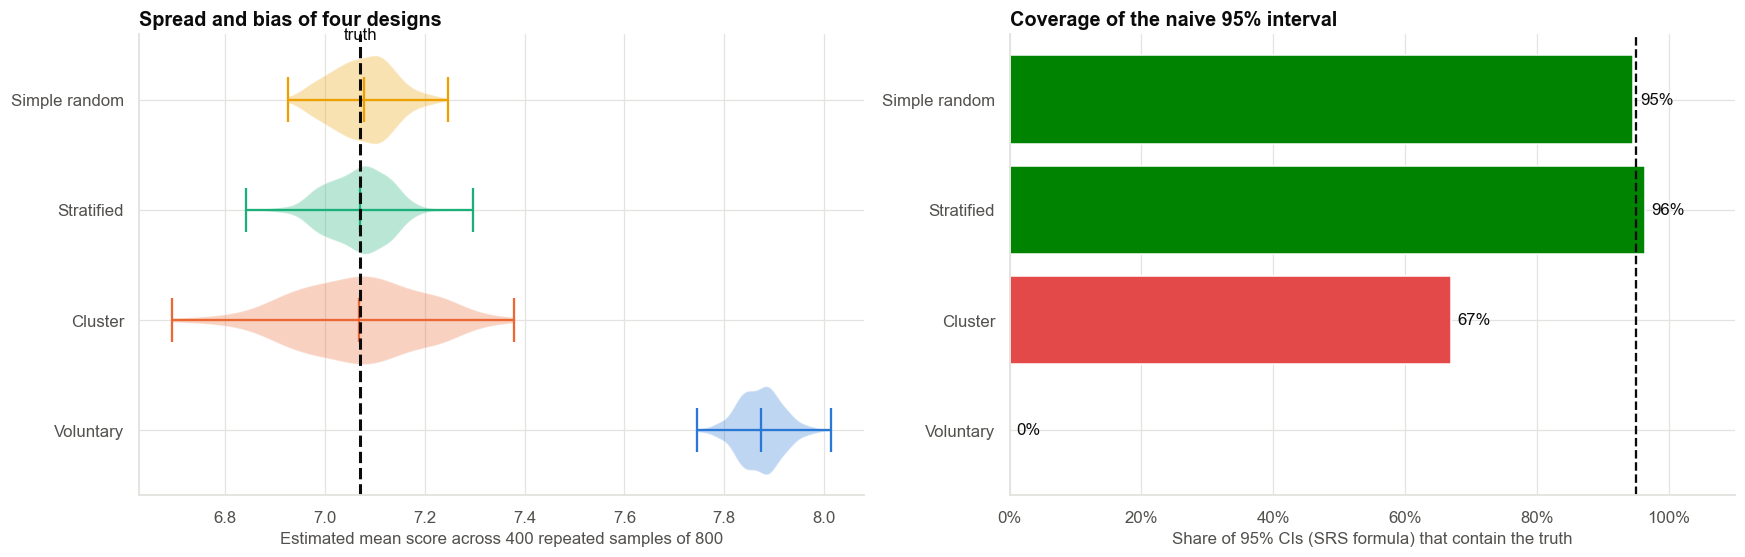

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
ax = axes[0]
for i, kind in enumerate(designs[::-1]):
    rs_ = np.array([y_pop[design_sample(kind, rng)].mean() for _ in range(400)])
    ax.violinplot(rs_, positions=[i], orientation="horizontal", widths=0.8, showmedians=True)
ax.axvline(mu, color=INK, ls="--", lw=2); ax.text(mu, 3.55, "truth", ha="center")
ax.set_yticks(range(len(designs)), [d.split(" (")[0] for d in designs[::-1]])
ax.set(xlabel="Estimated mean score across 400 repeated samples of 800", title="Spread and bias of four designs")
ax = axes[1]
cv = sim_d["95% CI coverage"][::-1]
ax.barh(range(len(cv)), cv, color=[COLORS["green"] if v > 0.9 else COLORS["red"] for v in cv])
ax.axvline(0.95, color=INK, ls="--")
for i, v in enumerate(cv):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center")
ax.set_yticks(range(len(cv)), [d.split(" (")[0] for d in cv.index]); ax.xaxis.set_major_formatter(pctfmt)
ax.set(xlim=(0, 1.1), xlabel="Share of 95% CIs (SRS formula) that contain the truth", title="Coverage of the naive 95% interval")
fig.tight_layout()
save_fig(fig, "fig05_design_simulation", PATHS["figures"])
plt.show()

**Observation.** Repeated samples of 800 from the *same* 40,000 customers:

| Design | Bias | True SE | Design effect | Coverage of the naive 95% CI |
|---|---|---|---|---|
| Simple random | 0.00 | 0.066 | 1.0 | 95% |
| Stratified (by complaints) | 0.00 | 0.061 | 0.85 | 96% |
| Cluster (8 branches × 100) | 0.00 | 0.129 | 3.8 | **67%** |
| Voluntary (800 email respondents) | **+0.80** | 0.046 | 0.48 | **0%** |

- A **simple random** sample is unbiased and the textbook formula is right.
- **Stratifying** gives slightly smaller error for the same size.
- **Cluster** sampling is unbiased but its true error is about twice the textbook figure (design effect 3.8), so the naive
  interval undercovers badly: customers in a branch resemble each other, so 800 clustered customers carry the
  information of about 210 independent ones.
- The **voluntary** sample has the *smallest* spread (SE 0.046) and **0% coverage**: it is precisely and consistently wrong.
  A small random sample (800) is far better than 2,058 volunteers, whose error is 0.80.

| Question | If YES | If NO |
|---|---|---|
| Is there a **frame** (list of everyone you want to describe) with known characteristics? | You can check representativeness and weight | You cannot measure bias; say so |
| Was selection **random**? | Standard CIs apply | Treat the CI as a lower bound on uncertainty; check bias |
| Is the **response rate** high (> 60%) and similar across groups? | Bias is limited | Compare respondents with the frame; weight |
| Response rate **low (< 20%)**? | Plan a **non-response follow-up** of a random sample of non-respondents | Fine, but still check groups |
| Does non-response plausibly depend on the **answer itself**? | Weighting is not enough: follow-up and tipping-point analysis | Weighting on frame variables may be adequate |
| Weights **extreme** (max ÷ median > 20, design effect > 3)? | Trim, collapse cells, use fewer variables; report effective n | Fine |
| Is the **frame** itself incomplete (leavers, non-customers)? | Say whom the result does **not** cover | – |
| Are there **groups** you must report on? | Stratify the design; oversample small groups | SRS is fine |

**Rules of thumb**

| Weighting variable choice | Do | Don't |
|---|---|---|
| Variables that predict **both** response and the outcome | Include (these remove the most bias) | – |
| Variables that predict only response | Fine, but add variance | Don't expect bias reduction |
| The outcome itself, or things caused by it | – | **Never** weight on the outcome |
| Many variables, sparse cells | Raking or response-propensity models | Avoid the full cross-classification |

## Section 14 — Results

In [15]:
summary = pd.DataFrame({"Value": [
    f"{len(r):,} of {N_pop:,} ({len(r) / N_pop:.1%}); response rates {rep['response rate'].min():.1%}–{rep['response rate'].max():.1%} across groups",
    f"mean {naive.iloc[0, 0]:.2f} (CI {naive.iloc[0, 1]:.2f}–{naive.iloc[0, 2]:.2f}), NPS {naive.iloc[3, 0]:+.0f}".replace("-", "−"),
    f"mean {grade.loc['Raked', 'mean score']:.2f}, NPS {grade.loc['Raked', 'NPS']:+.0f}; effective sample size {wd.loc['Raking', 'effective sample size']:.0f} of {len(r):,}".replace("-", "−"),
    f"{f_s.mean():.2f} (n = {nf}) vs {r['score'].mean():.2f} for respondents; combined estimate {comb:.2f}",
    f"mean {true_mean:.2f}, NPS {100 * (tp - td):+.0f}; including customers who left: {true_all:.2f}".replace("-", "−"),
    f"naive bias {grade.loc['Unweighted (naive)', 'bias']:+.2f}; raked bias {grade.loc['Raked', 'bias']:+.2f}; IPW bias {grade.loc['Inverse propensity', 'bias']:+.2f}".replace("-", "−"),
]}, index=["Response", "Naive result", "Raked result", "Follow-up", "Truth", "Bias of mean score"])
save_table(summary, "results_summary", PATHS["tables"])
summary

,Value
Response,"2,058 of 40,000 (5.1%); response rates 1.8%–11..."
Naive result,"mean 7.87 (CI 7.80–7.94), NPS +19"
Raked result,"mean 7.63, NPS +9; effective sample size 1323 ..."
Follow-up,7.28 (n = 246) vs 7.87 for respondents; combin...
Truth,"mean 7.07, NPS −13; including customers who le..."
Bias of mean score,naive bias +0.80; raked bias +0.56; IPW bias +...


## Section 15 — Interpretation

- **A narrow margin of error is not evidence of accuracy.** The naive survey was precise (±0.07) and wrong (+0.80).
- **Who answers is partly predictable** from what we know about customers (age, app use, complaints), and **partly
  unpredictable** (happier customers answer more, even within groups).
- **Weighting removes the predictable part of the bias** (about 30% here) at a cost in effective sample size (2,058 → about 1,320).
  A follow-up of a small random sample of non-respondents shows more of what is left; it moves the estimate to 7.31 but,
  because only 60% are reached, even that overstates satisfaction.
- **Survivorship matters:** customers who left are not in the frame, and they scored 5.23. Even a perfect
  estimate for active customers (7.07) overstates the experience of everyone served this year (6.83).

## Section 16 — What can we say?

| ✅ We can say | ❌ We cannot say |
|---|---|
| "Among the 5% who replied, the average score was 7.9." | "Our customers' average satisfaction is 7.9." |
| "After weighting to the customer base, the estimate is about 7.6 (95% CI 7.55–7.72), and a random phone follow-up suggests it is lower still (about 7.3)." | "The margin of error is ±0.07." (That ignores bias and the weighting variance.) |
| "Randomly sampled non-respondents scored about 0.6 points lower than respondents." | "Non-respondents are like respondents." |
| "This applies to active customers, not to those who left." | "Satisfaction is a record." (Needs a consistent method and the same response pattern as past years.) |

## Section 17 — Business interpretation

- **Annual report:** do **not** publish 7.9 or +19. If a figure must appear, state the follow-up-adjusted range
  (about 7.3 to 7.6), the response rate (5%), who it covers, and that NPS is likely near or below zero.
- **Trend reporting:** compare years only with the **same method and weights**. A change in response mix looks like a
  change in satisfaction.
- **Next survey:** invite a **random sample** with several contact waves and a follow-up of non-respondents, and
  **stratify** on age, app use and complaints so that small groups are heard.

## Section 18 — Limitations

- Weights use only variables on the frame; hidden drivers of response remain (and here they are strong).
- The follow-up reaches 60% of its sample; mode effects are not modelled.
- Simulated population with a known structure; the strength of the score-dependent response (0.22 per point) is a choice.
- The NPS definition (9–10 vs 0–6) discards information; the mean score tells the same story here.

## Section 19 — Final recommendation

> **Do not report the raw 7.9 / NPS +19.** Report a range, not a point: the raked estimate (7.6; NPS about +9) is an upper
> bound for active customers who answer email, and the phone follow-up (7.3) is closer. State the response rate and the
> population covered. For the next survey, use a **stratified random sample** with reminder waves and a **random
> non-response follow-up**.

## Section 20 — What would I do next?

1. Run a **random-sample survey** (stratified by age band, app use and complaints) with 3 contact waves, and compare
   with the voluntary survey.
2. Add an **exit survey** for leavers to cover the survivorship gap.
3. Set up **response-rate monitoring by group** for every future survey.
4. Calibrate to more known variables (product holdings, transaction volume) if they predict both response and
   satisfaction.
5. Continue to **Case 19** (many segments, many tests: how to avoid false discoveries).